In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder

In [9]:
import os
os.makedirs("visuals", exist_ok=True)

In [13]:
# Load dataset
df = pd.read_csv("WA_Fn-UseC_-HR-Employee-Attrition.csv")

In [18]:
# Initial Overview
print("Initial shape:", df.shape)
print("Missing values:\n", df.isnull().sum())
print("Duplicates:", df.duplicated().sum())

Initial shape: (1470, 35)
Missing values:
 Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany             

In [17]:
# Drop duplicates
df = df.drop_duplicates()

In [14]:
# Convert 'Attrition' column to binary
df['Attrition'] = df['Attrition'].map({'Yes': 1, 'No': 0})

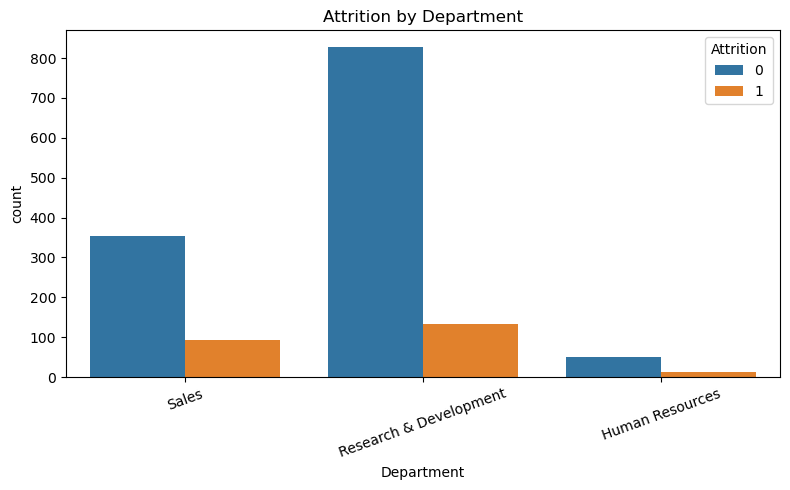

In [10]:
# EDA: Attrition by Department
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='Department', hue='Attrition')
plt.title('Attrition by Department')
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig("visuals/attrition_by_department.png")
plt.show()

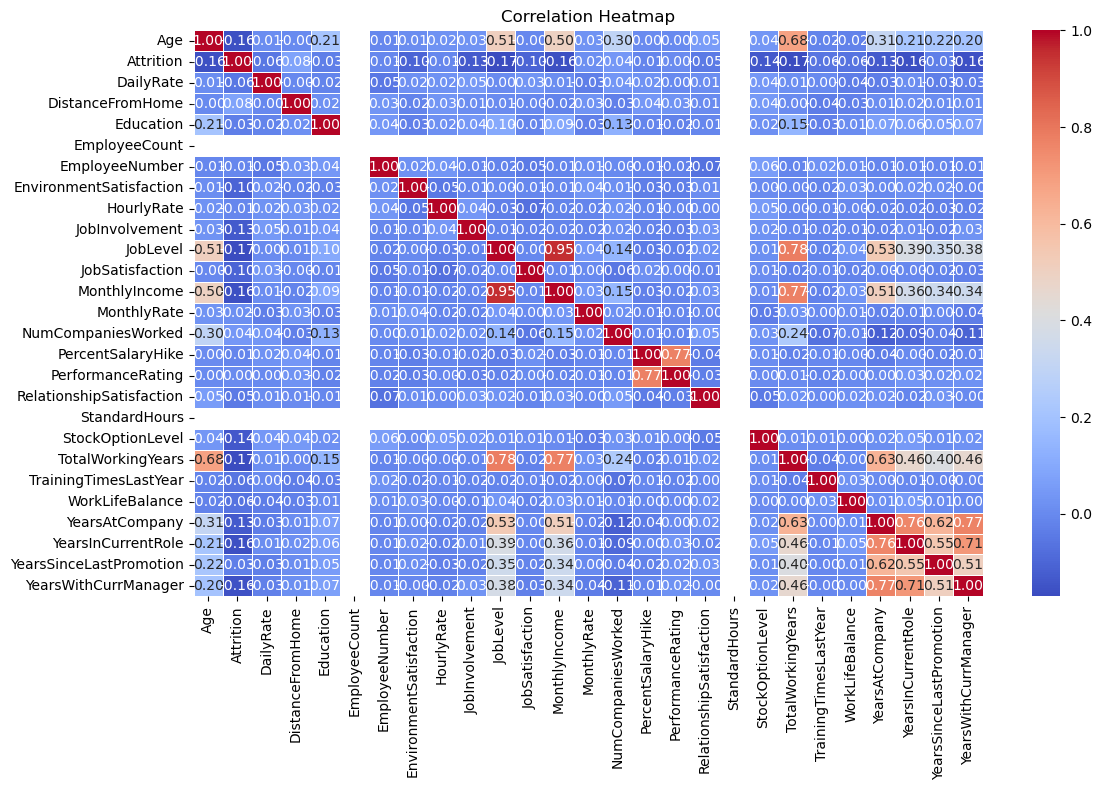

In [12]:
# EDA: Correlation Heatmap (Numeric Columns Only)
plt.figure(figsize=(12, 8))

# ✅ Select only numeric columns
numeric_df = df.select_dtypes(include='number')

# ✅ Compute correlation
corr = numeric_df.corr()

# ✅ Plot heatmap
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig("visuals/correlation_heatmap.png")
plt.show()
